# Second-round models: physics-structured outputs (A), hierarchical GP (B), calibrated error bars (H), decomposed optimization (F)

The first round (`notebooks/ml_models_walkthrough.ipynb`) asked generic models to learn $\sigma_e$, $\lambda$ and the gain from scratch.
What it taught us:

* the remaining $\sigma_e$ error came from information the hand-made features did not carry (an intermittent noise floor), and only a
  data-hungry CNN on the curves recovered it (~480 packets);
* a **new module** was the hardest case: ~20 of its packets were needed;
* $\sigma_e$, $\lambda$ and the gain are linked by physics that the models had to rediscover;
* some error bars (the boosted trees') were too narrow.

This notebook builds the second-round models in `src/ml/structured.py`, `src/ml/calibrate.py` and `src/ml/benchmark_structured.py`:

| Model | Idea |
|---|---|
| **A** physics-structured | measure $\sigma_1$ and the noise floor on the trace; learn only the gain and a small correction; $\lambda$ = dark current + CIC |
| **B** hierarchical GP | one GP whose kernel knows amplifiers and modules: shared behaviour + each module's and amplifier's own offset |
| **H** conformal calibration | rescale any model's error bars on held-out packets so that 68 % / 95 % mean what they say |
| **F** decomposed surrogate | in Bayesian optimization, model $\sigma_e$ and $\lambda$ separately and combine them, instead of one GP on the objective |

The document version is the section "Prototypes of the next models" of `docs/overleaf_ml_models/ml_models.tex`.
Everything runs on the synthetic world (`src/ml/synthetic.py`): the numbers compare methods, not the real CCD.

In [1]:
import sys, json, warnings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
warnings.filterwarnings("ignore")

PROJECT = Path.cwd().parent
sys.path.insert(0, str(PROJECT / "src"))
from ml import synthetic, data, models, evaluate, structured as st, calibrate
from ml.benchmark_structured import TARGETS, truth_targets

plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3, "font.size": 9})
RESULTS = PROJECT / "docs" / "ml_results"           # written by: python -m ml.benchmark_structured

## 1. Two synthetic worlds

* **v2** is the world of the first round. The trace physics is complete: $\sigma_e^2 = \sigma_1^2/N + \sigma_\text{floor}^2$ in electrons,
  and the trace measures $\sigma_1$ and the floor (in ADU).
* **v3** adds two things that make the test harder and closer to reality:
  * a noise term that **only the image sees** (low-frequency noise over the 4.8-min image that a 0.2-s trace of 10 pixels cannot
    measure), depending on VR and the H-clock hold; on average 29 % of $\sigma_e$;
  * $\lambda$ measured **row by row**: with EXPOSURE 0, a pixel of row $r$ collects dark current while the rows below it are read, so
    $\lambda_r = \text{CIC} + \text{DC}\,(r+\tfrac12)/8$; a straight line through the 16 rows splits the two.

The defaults of `make_dataset` give v2 exactly (checked against the first round's code).

In [2]:
v2, c2 = synthetic.make_dataset(60, seed=1)
v3, c3 = synthetic.make_dataset(60, seed=1, image_only_noise=True, per_row_lambda=True)
print("v3: image-only noise / sigma_e:", (v3["truth.image_only"] / v3["truth.sigma_e"]).describe()[["mean", "min", "max"]].round(2).to_dict())
for part in ("dark", "cic"):
    err = np.log(v3[f"label.lambda_{part}"].clip(1e-4) / v3[f"truth.{part}"])
    print(f"per-row fit of the {part:4s} part: scatter {err.std():.2f} (log)")

# one image's rows
rng = np.random.default_rng(0)
amp = synthetic.make_amplifiers(np.random.default_rng(1234))[0]
ph = synthetic.physics(synthetic.NOMINAL, amp, 0.0)
x = (np.arange(16) + 0.5) / 8
rows = (ph["cic"] + ph["dark"] * x) * (1 + synthetic.ROW_LAMBDA_SD * rng.normal(size=16))
slope, intercept = np.polyfit(x, rows, 1)
fig, ax = plt.subplots(figsize=(6, 3.2))
ax.plot(np.arange(16), rows, "o", label="measured row by row")
ax.plot(np.arange(16), intercept + slope * x, "-", label=f"fit: CIC {intercept:.3f} + dark {slope:.3f} (r+1/2)/8")
ax.axhline(ph["cic"], color="0.5", ls=":", label=f"true CIC {ph['cic']:.3f}")
ax.set(xlabel="row (read order)", ylabel="lambda (e-/pixel)", title="Dark charge row by row (nominal settings, toy)")
ax.legend(fontsize=7); plt.tight_layout(); plt.show()

v3: image-only noise / sigma_e: {'mean': 0.28, 'min': 0.05, 'max': 0.56}
per-row fit of the dark part: scatter 0.13 (log)
per-row fit of the cic  part: scatter 0.15 (log)


## 2. Model A: the physics on the trace

The trace's Allan deviation (scatter of $n$-skip averages) follows $\sigma_A(n)^2 = a^2/n + b^2$, with $a = \sigma_1 g$ (single-skip noise
in ADU) and $b = \sigma_\text{floor}\,g$. `allan_fit` fits it, one weighted least-squares problem per row. With the gain $g$ from a
model, the read noise of the image follows without learning anything:

$$\log\sigma_e = \tfrac12\log\!\left(\frac{a^2}{N} + b^2\right) - \log g + r(x),$$

where $r(x)$ is a learned correction for whatever the image sees and the trace does not (0 in v2, the image-only term in v3).

In [3]:
a, b = st.allan_fit(c2["noise: Allan deviation"], synthetic.ALLAN_N)
g = v2["truth.gain"].to_numpy()
fig, axes = plt.subplots(1, 3, figsize=(13, 3.6))
axes[0].loglog(v2["truth.sigma1"], a / g, ".", ms=4); axes[0].plot([3, 40], [3, 40], "k:")
axes[0].set(xlabel="true sigma_1 (e-)", ylabel="a / g from the Allan fit", title="single-skip noise")
axes[1].plot(v2["truth.floor"], b / g, ".", ms=4); axes[1].plot([0, 0.4], [0, 0.4], "k:")
axes[1].set(xlabel="true floor (e-)", ylabel="b / g", title="noise floor (intermittent pickup)")
for on, color in ((0, "C0"), (1, "C3")):
    i = int(np.flatnonzero((v2["truth.pickup"] == on) & (v2["channel"] == 0))[0])
    axes[2].loglog(synthetic.ALLAN_N, c2["noise: Allan deviation"][i], "o", color=color, ms=3, label=f"pickup {'on' if on else 'off'}")
    n = np.logspace(0, 2.3, 50)
    axes[2].loglog(n, np.sqrt(a[i] ** 2 / n + b[i] ** 2), "-", color=color, lw=1)
axes[2].set(xlabel="skips averaged n", ylabel="Allan deviation (ADU)", title="fit a^2/n + b^2"); axes[2].legend(fontsize=7)
plt.tight_layout(); plt.show()
phys = 0.5 * np.log(a ** 2 / 500 + b ** 2) - np.log(g)
print("sigma_e from the trace with the TRUE gain, error against the truth: %.2f %%" % (100 * np.std(phys - np.log(v2["truth.sigma_e"]))))

sigma_e from the trace with the TRUE gain, error against the truth: 2.88 %


With the true gain, the trace alone gives $\sigma_e$ to about 3 % (the precision of the Allan fit; A+B's learned correction brings it to
2 %). So in model A only the gain, which the trace cannot see because it
measures $\sigma_1 g$ and not $\sigma_1$, has to be learned, plus the correction $r(x)$.

## 3. The packet state vector

The dark charge drifts with a hidden state (temperature, history). The reference traces see it. `StructuredPrep` turns them into a
**packet state vector**: each amplifier's reference features minus that amplifier's average on the training packets, averaged over the
amplifiers of the packet. The amplifier signatures cancel and the state remains. For an amplifier never seen, the state comes from the
other amplifiers of the same packet, so the inputs must be built on **whole packets**.

In [4]:
prep = st.StructuredPrep().fit(v2)
S = prep.state_vector(v2)
names = prep.ref_cols
j = names.index("ref.skip: baseline at skip 1")
fig, ax = plt.subplots(figsize=(5, 3.4))
ax.plot(v2["truth.state"], S[:, j], ".", ms=4)
ax.set(xlabel="true hidden state", ylabel="state vector: baseline at skip 1 (ADU)", title="the reference traces measure the state")
plt.tight_layout(); plt.show()
print("correlation with the true state: %.3f" % np.corrcoef(v2["truth.state"], S[:, j])[0, 1])

correlation with the true state: 1.000


## 4. Model B: the hierarchical Gaussian process

$$k(x,x') = s^2 M(x,x') + [\text{same module}]\,(c_m^2 + s_m^2 M) + [\text{same amplifier}]\,(c_a^2 + s_a^2 M) + \text{noise}^2,$$

with $M$ a Matérn-5/2 kernel with one length scale per input. The fit decides how much of the target is shared and how much belongs to
each amplifier. For the gain almost everything is the amplifier's own level, as expected: the four amplifiers differ by a factor 2.

In [5]:
Xp = prep.transform(v2, c2)
Y, _ = data.make_targets(v2)
gp = st.HierGP().fit(Xp, Y[:, 2])
print("log gain, fitted amplitudes (units of the target's sd):", {k: round(v, 3) for k, v in gp.hyperparameters().items()})

log gain, fitted amplitudes (units of the target's sd): {'s': 0.001, 'noise': 0.024, 'c_module': 0.001, 's_module': 0.088, 'c_amp': 0.997, 's_amp': 0.013}


## 5. First comparison (60 training packets, live)

Trained on 60 packets, tested on 200 new ones; error against the labels and against the noise-free truth. The labels themselves scatter
by 1.5 % ($\sigma_e$), 3 % ($\lambda$) and 0.8 % (gain), so errors against the labels cannot go below those values.

In [6]:
def compare(world_kw, n_train=60, n_test=200, with_split=False):
    tr, ctr = synthetic.make_dataset(n_train, seed=1, **world_kw)
    te, cte = synthetic.make_dataset(n_test, seed=99, **world_kw)
    Ytr, Yte, Ytruth = data.make_targets(tr)[0], data.make_targets(te)[0], truth_targets(te)
    prep = st.StructuredPrep().fit(tr)
    Xtr, Xte = prep.transform(tr, ctr), prep.transform(te, cte)
    rows = {}
    Ftr, _ = data.make_inputs(tr, ("theta", "amp", "trace", "ref"), drop_constant=False)
    Fte, _ = data.make_inputs(te, ("theta", "amp", "trace", "ref"), drop_constant=False)
    m, s = models.GP().fit(Ftr, Ytr).predict(Fte)
    rows["first round: GP, theta + amp + features"] = (m, s)
    plan = {"B: hierarchical GP": st.DirectGP("hier"), "A: physics + ordinary GP": st.PhysicsStructured("plain", use_components=False),
            "A+B": st.PhysicsStructured("hier", use_components=False),
            "A+B, floor not measured": st.PhysicsStructured("hier", use_components=False, use_floor=False)}
    if with_split:
        plan["A+B, lambda = dark + CIC"] = st.PhysicsStructured("hier", use_components=True)
    for label, model in plan.items():
        rows[label] = model.fit(Xtr, Ytr, st.component_targets(tr)).predict(Xte)
    table = {}
    for label, (m, s) in rows.items():
        sl, stt = evaluate.scores(Yte, m, s, TARGETS), evaluate.scores(Ytruth, m, s, TARGETS)
        table[label] = {**{f"{t} vs labels %": 100 * sl[t]["rel_error"] for t in TARGETS},
                        **{f"{t} vs truth %": 100 * stt[t]["rel_error"] for t in TARGETS},
                        **{f"{t} coverage": sl[t]["coverage"] for t in TARGETS}}
    return pd.DataFrame(table).T.round(2)

print("world v2"); display(compare({}))
print("world v3"); display(compare({"image_only_noise": True, "per_row_lambda": True}, with_split=True))

world v2


,sigma_e vs labels %,lambda vs labels %,gain vs labels %,sigma_e vs truth %,lambda vs truth %,gain vs truth %,sigma_e coverage,lambda coverage,gain coverage
"first round: GP, theta + amp + features",15.26,5.28,0.86,15.23,4.42,0.27,0.68,0.56,0.65
B: hierarchical GP,14.63,7.44,0.85,14.55,6.94,0.22,0.67,0.75,0.71
A: physics + ordinary GP,2.68,8.09,0.93,2.15,7.63,0.41,0.68,0.70,0.68
A+B,2.49,7.44,0.85,1.96,6.94,0.22,0.70,0.75,0.71
"A+B, floor not measured",14.69,7.44,0.85,14.65,6.94,0.22,0.74,0.75,0.71


world v3


,sigma_e vs labels %,lambda vs labels %,gain vs labels %,sigma_e vs truth %,lambda vs truth %,gain vs truth %,sigma_e coverage,lambda coverage,gain coverage
"first round: GP, theta + amp + features",13.75,4.57,0.91,13.64,3.11,0.49,0.60,0.70,0.60
B: hierarchical GP,13.76,6.98,1.02,13.65,6.22,0.65,0.58,0.80,0.61
A: physics + ordinary GP,3.46,7.52,0.95,3.16,6.80,0.58,0.65,0.77,0.70
A+B,3.39,6.98,1.02,3.12,6.22,0.65,0.66,0.80,0.61
"A+B, floor not measured",13.02,6.98,1.02,12.94,6.22,0.65,0.60,0.80,0.61
"A+B, lambda = dark + CIC",3.39,10.09,1.02,3.12,9.57,0.65,0.66,0.90,0.61


**Reading the tables:**

* **A cuts the $\sigma_e$ error by a factor 5–7** at 60 packets, because it measures what the other models must learn. In v3 the learned
  correction $r(x)$ recovers most of the image-only term (about 3 % against 14 % for the first round).
* **Without the floor measurement** ($b = 0$), A loses that advantage. The trace must be long enough to see the floor (the Allan curve
  to $n \approx 160$ needs $\geq 320$ skips; the packets use 500).
* **B alone** does not fix $\sigma_e$: it sees the same information as the first round. It is better for the gain and the error bars.
* **Splitting $\lambda$ into dark + CIC** did not pay off in the benchmark (worse from 30 packets on, error bars too wide): with 16 rows
  each part of one image is measured to 13–15 % with anti-correlated errors, while their sum is known to 3 %; two separate fits throw that
  away (a joint likelihood would not). The per-row $\lambda$ is still a useful physics check on real data.

## 6. Error against the number of training packets (benchmark)

world v2: sigma_e error against the truth (%)


,15,30,60,120,240,480
B: hierarchical GP,18.0,16.6,14.6,15.0,13.6,12.0
A: physics + ordinary GP,2.6,2.5,2.2,2.0,2.0,2.0
A+B: physics + hierarchical GP,2.4,2.0,2.0,2.0,2.0,2.0
"A+B, noise floor not measured",16.9,14.8,14.6,12.7,13.1,12.1
"first round: GP, theta + amp + features",18.2,19.8,15.2,13.0,11.6,13.5
"first round: CNN, curves + theta + amp",NaN,NaN,12.7,NaN,8.5,1.2


world v2: lambda error against the truth (%)


,15,30,60,120,240,480
B: hierarchical GP,21.3,10.2,6.9,2.9,1.6,1.3
A: physics + ordinary GP,22.2,11.0,7.6,3.1,1.6,1.4
A+B: physics + hierarchical GP,21.3,10.2,6.9,2.9,1.6,1.3
"A+B, noise floor not measured",21.3,10.2,6.9,2.9,1.6,1.3
"first round: GP, theta + amp + features",19.9,8.5,4.4,2.1,2.0,2.2
"first round: CNN, curves + theta + amp",NaN,NaN,11.1,NaN,4.2,2.3


world v3: sigma_e error against the truth (%)


,15,30,60,120,240,480
B: hierarchical GP,15.4,15.5,13.6,11.4,10.2,10.8
A: physics + ordinary GP,3.2,4.5,3.2,2.5,2.3,2.2
A+B: physics + hierarchical GP,3.3,4.4,3.1,2.4,2.2,2.2
"A+B, noise floor not measured",12.4,12.7,12.9,9.8,9.9,10.4
"A+B, lambda = dark + CIC",3.3,4.4,3.1,2.4,2.2,2.2
"first round: GP, theta + amp + features",17.2,15.9,13.6,10.6,10.3,10.7
"first round: CNN, curves + theta + amp",NaN,NaN,10.6,NaN,7.7,1.5


world v3: lambda error against the truth (%)


,15,30,60,120,240,480
B: hierarchical GP,40.7,17.9,6.2,3.9,1.6,1.5
A: physics + ordinary GP,39.2,19.5,6.8,4.2,1.7,1.5
A+B: physics + hierarchical GP,40.7,17.9,6.2,3.9,1.6,1.5
"A+B, noise floor not measured",40.7,17.9,6.2,3.9,1.6,1.5
"A+B, lambda = dark + CIC",33.6,31.3,9.6,5.7,2.3,2.3
"first round: GP, theta + amp + features",28.2,12.6,3.1,2.8,2.2,2.2
"first round: CNN, curves + theta + amp",NaN,NaN,16.6,NaN,4.4,2.6


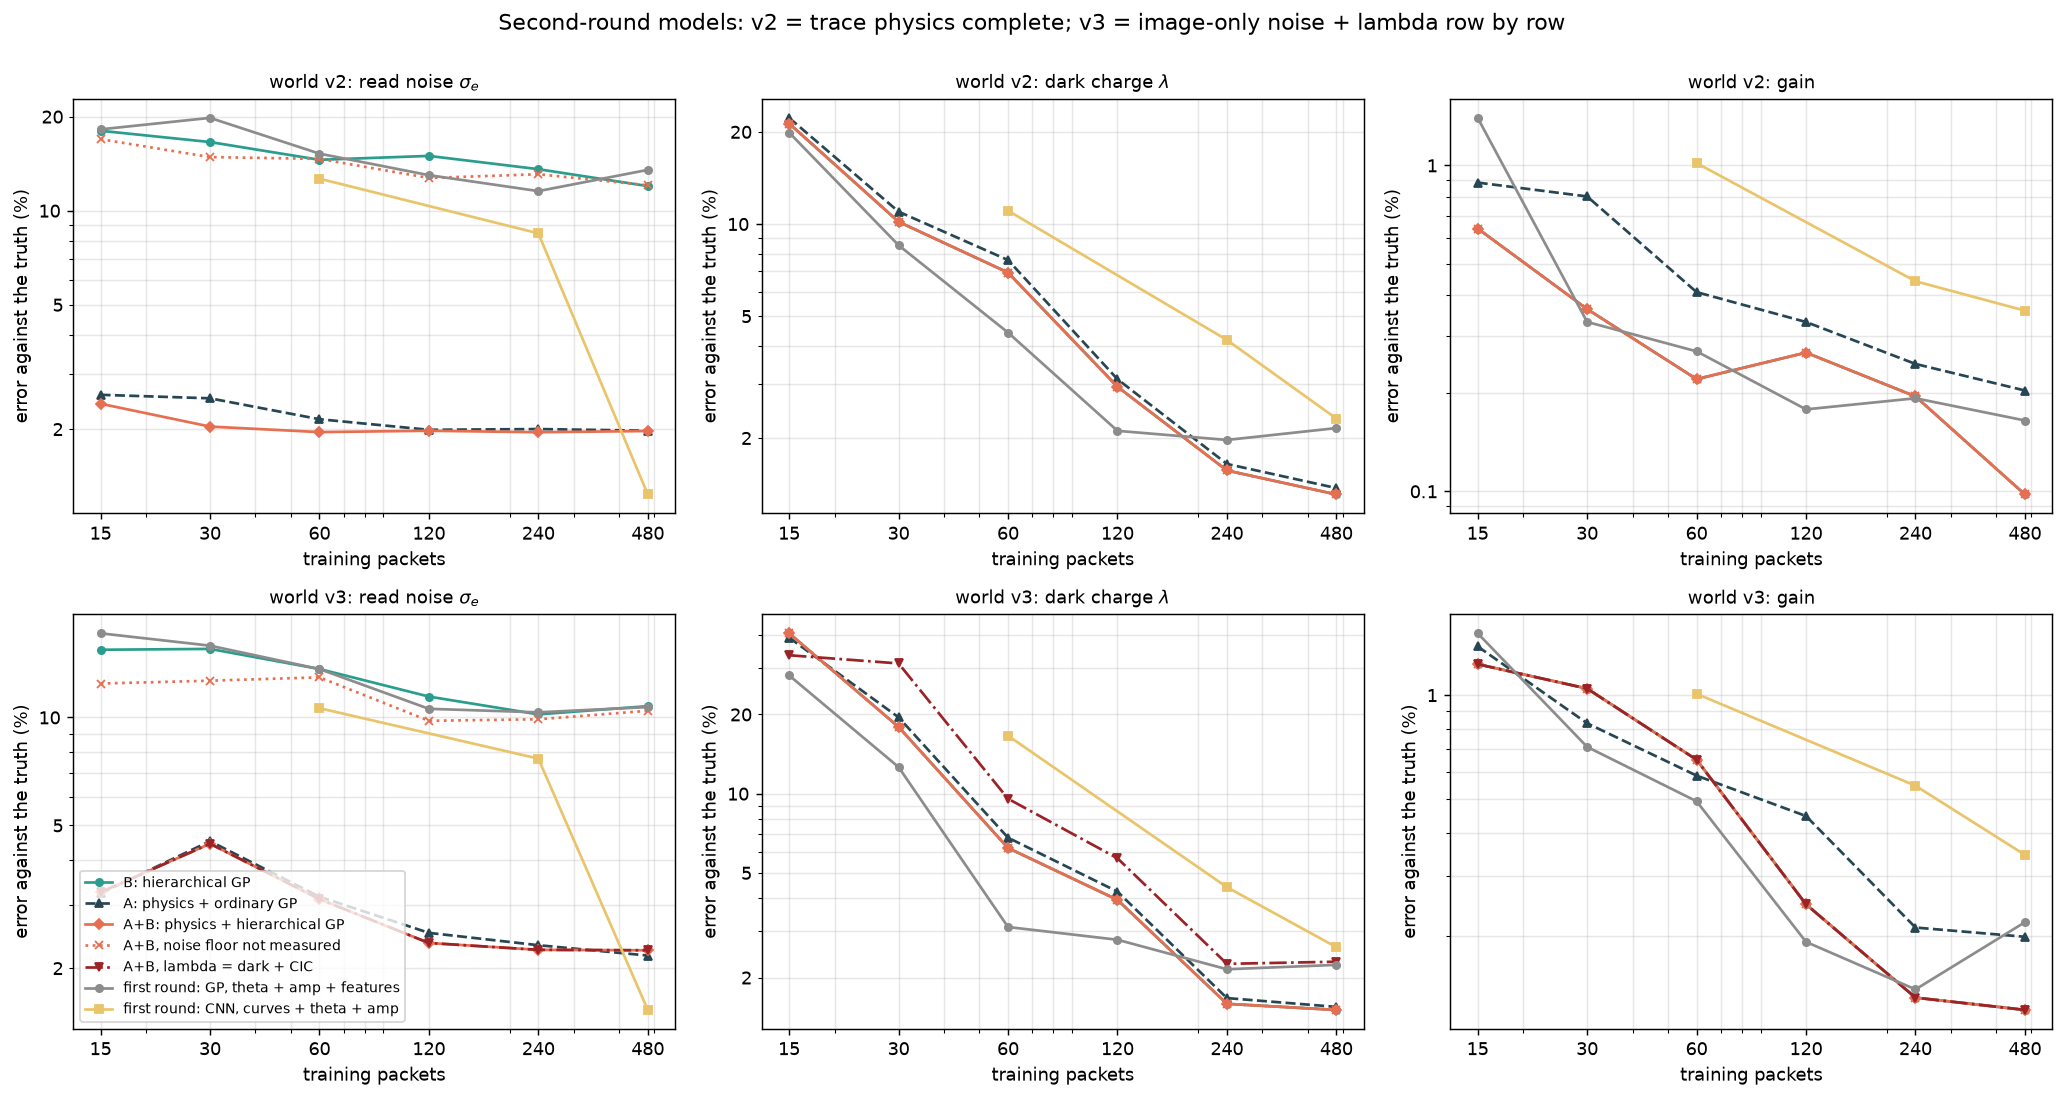

In [7]:
L = json.loads((RESULTS / "structured_learning.json").read_text())
for world in L:
    tab = {label: {int(n): 100 * r["truth"][t]["rel_error"] for n, r in by_n.items()} for label, by_n in L[world].items() for t in ["sigma_e"]}
    print(f"world {world}: sigma_e error against the truth (%)")
    display(pd.DataFrame(tab).T.round(1))
    tab = {label: {int(n): 100 * r["truth"]["lambda"]["rel_error"] for n, r in by_n.items()} for label, by_n in L[world].items()}
    print(f"world {world}: lambda error against the truth (%)")
    display(pd.DataFrame(tab).T.round(1))
from IPython.display import Image
display(Image(str(PROJECT / "docs/overleaf_ml_models/figures/ml_structured_learning.png"), width=950))

## 7. A module never seen in training

Trained on 240 packets of module 100 plus $k$ packets of module 101; tested on module 101's other packets.

In [8]:
N = json.loads((RESULTS / "structured_newmodule.json").read_text())
for t in TARGETS:
    print(f"{t}: error on the new module (%), by number k of its packets in training")
    display(pd.DataFrame({label: {int(k): 100 * r["labels"][t]["rel_error"] for k, r in by_k.items()} for label, by_k in N.items()}).T.round(1))

sigma_e: error on the new module (%), by number k of its packets in training


,0,1,2,5,10,20
"first round: GP, theta + amp + features",72.0,24.4,17.7,15.6,14.4,14.7
"first round: boosted trees, theta + amp + features",57.3,39.1,38.0,19.1,19.6,13.9
B: hierarchical GP,57.7,7.1,7.4,7.3,6.8,6.1
A: physics + ordinary GP,43.8,3.9,2.6,2.6,2.5,2.5
A+B: physics + hierarchical GP,33.1,3.3,2.4,2.4,2.4,2.4


lambda: error on the new module (%), by number k of its packets in training


,0,1,2,5,10,20
"first round: GP, theta + amp + features",117.9,37.4,38.8,37.1,35.4,15.5
"first round: boosted trees, theta + amp + features",50.2,30.6,25.4,16.6,17.5,16.1
B: hierarchical GP,3.6,3.1,3.1,3.3,3.1,3.1
A: physics + ordinary GP,3.1,37.2,6.3,4.4,3.7,3.3
A+B: physics + hierarchical GP,3.6,3.1,3.1,3.3,3.1,3.1


gain: error on the new module (%), by number k of its packets in training


,0,1,2,5,10,20
"first round: GP, theta + amp + features",35.3,3.3,3.1,2.5,1.5,1.2
"first round: boosted trees, theta + amp + features",41.3,19.5,19.9,9.1,9.4,6.7
B: hierarchical GP,33.2,3.4,0.9,0.9,0.9,0.9
A: physics + ordinary GP,43.7,2.5,1.5,1.4,1.2,1.0
A+B: physics + hierarchical GP,33.2,3.4,0.9,0.9,0.9,0.9


* With **no** packet of the new module, nothing predicts its gain (the trace measures $\sigma_1 g$, never $g$ alone), so $\sigma_e$ is off
  by the module-to-module gain spread. The hierarchical GP says so: its error bars stay honest (coverage ~0.75), the others' collapse.
* $\lambda$ does not depend on the module here, and A+B / B predict it from the settings and the state of the *other* module's reference
  traces: ~3 %, against 50–120 % for the first round.
* **One or two imaged packets** of a new module bring A+B to the level of a known module. The first round needed ~20.

## 8. The scan design: one-at-a-time or random points?

The planned scan changes one parameter at a time (10 parameters × 20 values). The models are then asked about points where several
parameters change together, which is where an optimizer looks. Same number of packets, tested on random points:

In [9]:
D = json.loads((RESULTS / "structured_design.json").read_text())
for t in TARGETS:
    print(f"{t}: error on random test points (%)")
    display(pd.DataFrame({d: {label: 100 * r["truth"][t]["rel_error"] for label, r in by_m.items()} for d, by_m in D.items()}).round(1))

sigma_e: error on random test points (%)


,one-at-a-time,random,"half one-at-a-time, half random"
"first round: GP, theta + amp + features",12.1,11.6,14.0
"first round: boosted trees, theta + amp + features",13.0,12.1,11.9
B: hierarchical GP,16.0,13.3,13.8
A+B: physics + hierarchical GP,2.1,1.9,2.0


lambda: error on random test points (%)


,one-at-a-time,random,"half one-at-a-time, half random"
"first round: GP, theta + amp + features",8.9,1.9,2.3
"first round: boosted trees, theta + amp + features",14.7,11.7,13.4
B: hierarchical GP,11.4,1.2,1.9
A+B: physics + hierarchical GP,11.4,1.2,1.9


gain: error on random test points (%)


,one-at-a-time,random,"half one-at-a-time, half random"
"first round: GP, theta + amp + features",0.5,0.3,0.3
"first round: boosted trees, theta + amp + features",1.1,0.5,0.5
B: hierarchical GP,0.4,0.2,0.2
A+B: physics + hierarchical GP,0.4,0.2,0.2


**One-at-a-time is the weak design for $\lambda$**: it depends on several clock rails together, and a one-at-a-time scan never changes two
of them at once (GP models: 9–11 % against 1.2–1.9 % after a random design). Half one-at-a-time, half random is almost as good as all random.
$\sigma_e$ from A+B hardly depends on the design, because it is measured on each packet's own traces.

## 9. Calibrated error bars (H)

Conformal calibration multiplies a model's std by a factor learned on held-out packets (5-fold, grouped by packet), separately for 68 %
and 95 %. Coverage on the test scan before and after:

In [10]:
C = json.loads((RESULTS / "structured_conformal.json").read_text())
rows = {}
for label, by_n in C.items():
    for n, r in by_n.items():
        for i, t in enumerate(TARGETS):
            rows[(label, int(n), t)] = {"68 % raw": r["coverage"]["raw 0.68"][i], "68 % conformal": r["coverage"]["conformal 0.68"][i],
                                       "95 % raw": r["coverage"]["raw 0.95"][i], "95 % conformal": r["coverage"]["conformal 0.95"][i],
                                       "factor 68": r["factors"]["0.68"][i]}
display(pd.DataFrame(rows).T.round(2))

68 % raw  68 % conformal  \
boosted trees, theta + amp + features 60  sigma_e      0.36            0.72   
                                          lambda       0.22            0.77   
                                          gain         0.60            0.67   
                                      240 sigma_e      0.44            0.63   
                                          lambda       0.59            0.72   
                                          gain         0.60            0.72   
NN ensemble, theta + amp + features   60  sigma_e      0.48            0.66   
                                          lambda       0.58            0.89   
                                          gain         0.76            0.57   
                                      240 sigma_e      0.71            0.72   
                                          lambda       0.72            0.70   
                                          gain         0.75            0.69   
CNN, curves + theta + amp             60  sigma_e      0.58            0.66   
                                          lambda       0.65            0.70   
                                          gain         0.78            0.52   
                                      240 sigma_e      0.78            0.70   
                                          lambda       0.61            0.66   
                                          gain         0.74            0.70   
A+B: physics + hierarchical GP        60  sigma_e      0.70            0.72   
                                          lambda       0.75            0.57   
                                          gain         0.71            0.71   
                                      240 sigma_e      0.70            0.64   
                                          lambda       0.72            0.67   
                                          gain         0.69            0.69   

                                                   95 % raw  95 % conformal  \
boosted trees, theta + amp + features 60  sigma_e      0.64            0.96   
                                          lambda       0.48            0.99   
                                          gain         0.76            0.96   
                                      240 sigma_e      0.73            0.94   
                                          lambda       0.87            0.96   
                                          gain         0.81            0.98   
NN ensemble, theta + amp + features   60  sigma_e      0.76            0.95   
                                          lambda       0.88            1.00   
                                          gain         0.96            0.93   
                                      240 sigma_e      0.92            0.96   
                                          lambda       0.96            0.97   
                                          gain         0.97            0.94   
CNN, curves + theta + amp             60  sigma_e      0.82            0.92   
                                          lambda       0.91            0.92   
                                          gain         0.96            0.87   
                                      240 sigma_e      0.99            0.99   
                                          lambda       0.92            0.94   
                                          gain         0.96            0.93   
A+B: physics + hierarchical GP        60  sigma_e      0.95            0.95   
                                          lambda       0.98            0.92   
                                          gain         0.94            0.96   
                                      240 sigma_e      0.95            0.95   
                                          lambda       0.98            0.95   
                                          gain         0.95            0.93   

                                                   factor 68  
boosted trees, theta + amp + feature

## 10. Decomposed surrogate for Bayesian optimization (F)

The objective is $J = \overline{\log\sigma_e + \tfrac12\log\lambda}$ over the good amplifiers. The first round fitted one GP to $J$. Here
two hierarchical GPs model $\log\sigma_e$ and $\log\lambda$ per amplifier, and $J$ is computed from them: each part depends on fewer
parameters, so each is easier to learn.

GP on the objective (first round)                    best true J after 20 / 30 / 60 packets: -2.715 / -2.773 / -2.814   (worst seed at 30: -2.747)
decomposed: hierarchical GPs on sigma_e and lambda   best true J after 20 / 30 / 60 packets: -2.787 / -2.805 / -2.808   (worst seed at 30: -2.797)
nominal settings: -2.494


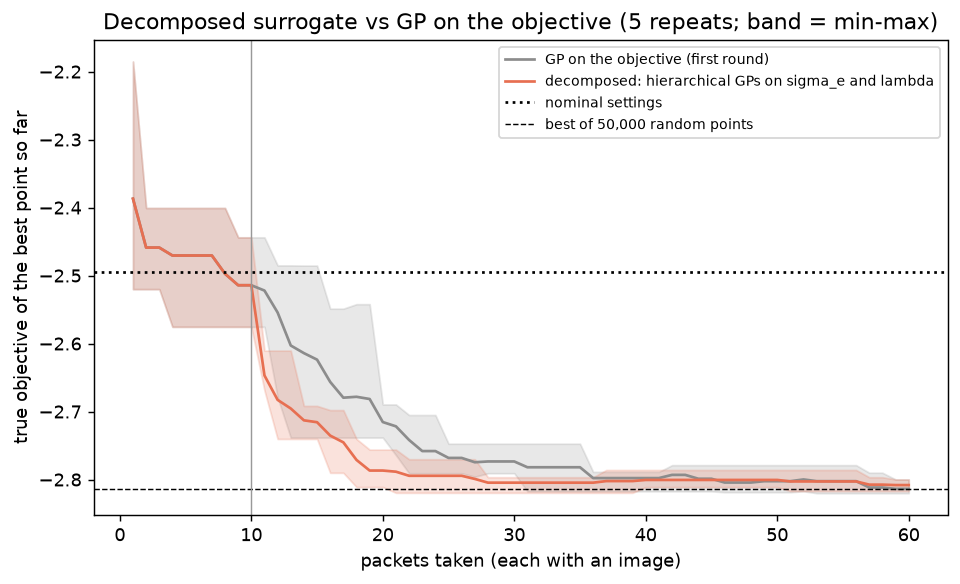

In [11]:
B = json.loads((RESULTS / "structured_bo.json").read_text())
for label, curves in B["curves"].items():
    arr = np.array(curves)
    print(f"{label:52s} best true J after 20 / 30 / 60 packets: {arr[:, 19].mean():.3f} / {arr[:, 29].mean():.3f} / {arr[:, -1].mean():.3f}"
          f"   (worst seed at 30: {arr[:, 29].max():.3f})")
print("nominal settings:", round(B["nominal"], 3))
display(Image(str(PROJECT / "docs/overleaf_ml_models/figures/ml_structured_bo.png"), width=650))

## 11. What this means for the real CCD

* **Test first whether the trace physics holds** (no training needed): with the image's gain, does $\sqrt{a^2/N + b^2}/g$ from the
  traces match the image's $\sigma_e$? The ratio and its dependence on the settings say how much A must learn.
* **Ask WADERs for $\lambda$ row by row** (and $\sigma$ per row): it separates dark current from CIC.
* **Make the scan design include joint changes** (random/Sobol points inside the limits, or half one-at-a-time, half random).
* **For every new module, take 2–5 imaged packets** first; traces alone cannot give its gain.
* **Keep the per-set features, the curves and the label errors** in the dataset (see "A better data format" in `ml_models.tex`).

The full plan to test every model on real data is in `ml_models.tex`, section "Testing every model on real data".